[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jalonso1979/puremacro/blob/course-2026A-5.5.0/curso/notebooks/T05_C_staggered_did_es.ipynb)

> **Nota para Google Colab**: la celda siguiente instala `puremacro` y, si hace falta, descarga del repositorio público [jalonso1979/puremacro](https://github.com/jalonso1979/puremacro) sólo la carpeta `curso/notebooks` de la edición `course-2026A-5.5.0` (auxiliares, datos congelados y modelos). No pide acceso a Google Drive.

In [1]:
# Configuración: Google Colab, Python local o Juno (iPad)
import os
import sys
import subprocess
from pathlib import Path

_course_requirements = ['puremacro==5.5.0']
_course_edition = 'course-2026A-5.5.0'

def _safe_probe(p, is_dir=None):
    """Test paths without raising in the Juno sandbox."""
    try:
        p = Path(p)
        if is_dir is True:
            return p.is_dir()
        if is_dir is False:
            return p.is_file()
        return p.exists()
    except (OSError, PermissionError, TypeError, ValueError):
        return False

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_course_requirements], check=True)
    # A separate directory per edition prevents reuse of helpers from another course.
    _repo = Path("/content/puremacro-" + _course_edition)
    if not _safe_probe(_repo, is_dir=True):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse",
                        "--branch", _course_edition, "https://github.com/jalonso1979/puremacro.git", str(_repo)], check=True)
    subprocess.run(["git", "-C", str(_repo), "checkout", "--detach", _course_edition], check=True)
    subprocess.run(["git", "-C", str(_repo), "sparse-checkout", "set", "curso/notebooks"], check=True)
    _course_status = subprocess.run(["git", "-C", str(_repo), "status", "--porcelain",
                                     "--untracked-files=normal", "--", "curso/notebooks"],
                                    check=True, capture_output=True, text=True).stdout
    if _course_status.strip():
        raise RuntimeError("The cached course edition was modified; use a fresh Colab runtime for the frozen edition.")
    os.chdir(_repo / "curso/notebooks")

# Locate the course helpers for local Python, Colab and Juno.
_candidates = [Path.cwd(), Path.cwd() / "notebooks", Path.cwd() / "curso/notebooks"]
try:
    _candidates.insert(0, Path(__file__).resolve().parent)
except (NameError, OSError):
    pass
for _c in _candidates:
    if _safe_probe(_c / "_nbstyle.py", is_dir=False):
        if str(_c) not in sys.path:
            sys.path.insert(0, str(_c))
        break

import puremacro
if puremacro.__version__ != "5.5.0":
    raise RuntimeError("This course edition requires puremacro==5.5.0; install it and restart the kernel.")

# Cached reference responses are the reproducible default; live models are optional.
os.environ.setdefault("MAV_LLM_MODE", "cache")

%matplotlib inline
try:
    import _nbstyle
    _nbstyle.apply_style()
except ImportError:
    pass

Matplotlib is building the font cache; this may take a moment.


# Diferencias en diferencias escalonadas y el colapso de los efectos fijos en dos vías

Al evaluar intervenciones macroeconómicas —desde variaciones en el salario mínimo legal o extensiones en la duración de las prestaciones por desempleo, hasta incentivos fiscales territoriales o programas de inversión pública— la investigación empírica se enfrenta con frecuencia a políticas adoptadas en momentos dispares entre distintas jurisdicciones. Durante décadas, la especificación empírica por defecto fue la regresión lineal con **efectos fijos en dos vías (TWFE)**:
$$ Y_{it} = \alpha_i + \lambda_t + \beta^{TWFE} D_{it} + \varepsilon_{it} $$
donde $\alpha_i$ recoge las características invariantes de la unidad, $\lambda_t$ absorbe las perturbaciones agregadas temporales y $D_{it} = \mathbb{1}\{t \ge G_i\}$ señala el estado de tratamiento.

Avances econométricos recientes (Goodman-Bacon 2021; de Chaisemartin & D'Haultfoeuille 2020; Sun & Abraham 2021; Callaway & Sant'Anna 2021) han demostrado que esta estrategia clásica colapsa bajo la presencia de efectos de tratamiento heterogéneos o dinámicos. Mínimos Cuadrados Ordinarios construye silenciosamente **comparaciones prohibidas**, utilizando a las unidades tratadas tempranamente —que ya experimentan una dinámica post-tratamiento en evolución— como "grupo de control" para las cohortes de adopción posterior. Diferenciar frente a una unidad ya tratada resta su trayectoria de tratamiento en curso, asignando **pesos negativos** a las observaciones tratadas. Ante dinámicas de despliegue gradual, $\hat{\beta}^{TWFE}$ puede invertir su signo por completo, reportando un coeficiente de política negativo cuando el efecto verdadero del tratamiento es estrictamente positivo en todas partes.

Este cuaderno analiza los fundamentos matemáticos de este fallo, descompone el sesgo de ponderación negativa mediante el teorema de Frisch-Waugh-Lovell y aplica estimadores modernos robustos a la heterogeneidad: los efectos medios de tratamiento por grupo-tiempo de **Callaway & Sant'Anna (2021)** y los estudios de eventos ponderados por interacciones de **Sun & Abraham (2021)**.

## Fundamentos econométricos: descomposición del fallo de TWFE

### Resultados potenciales y cohortes temporales
Considere un panel de unidades $i = 1, \dots, N$ observadas a lo largo de períodos $t = 1, \dots, T$. La unidad $i$ adopta la política en la fecha calendario $G_i \in \{g_1, g_2, \dots, g_K\} \cup \{\infty\}$, donde $G_i = \infty$ identifica a las unidades nunca tratadas. Para cada período $t$, sea $Y_{it}(0)$ el resultado potencial sin tratamiento y $Y_{it}(g)$ el resultado potencial si se adopta en la fecha $g$. El resultado observado es:
$$ Y_{it} = Y_{it}(0) + \sum_{g} \mathbb{1}\{G_i = g, t \ge g\}\,\tau_{it}(g, t) $$
donde $\tau_{it}(g, t) = Y_{it}(g) - Y_{it}(0)$ es el efecto causal específico de la unidad tras una exposición transcurrida $e = t - g$.

### La descomposición 2x2 de Goodman-Bacon (2021)
Goodman-Bacon demostró que el coeficiente de regresión lineal $\hat{\beta}^{TWFE}$ es un promedio ponderado exacto por varianza de todos los estimadores $2 \times 2$ de diferencias en diferencias posibles entre cohortes temporales:
$$ \beta^{TWFE} = \sum_{k \neq U} s_{kU} \beta_{kU}^{2 \times 2} + \sum_{k} \sum_{j > k} \left[ s_{kj}^k \beta_{kj}^{2 \times 2, k} + s_{jk}^j \beta_{jk}^{2 \times 2, j} \right] $$
donde los pesos $s$ son positivos y suman 1. Las tres clases de comparaciones $2 \times 2$ son:
1. **Tratadas vs. No tratadas ($\beta_{kU}^{2 \times 2}$)**: La cohorte $k$ comparada con las unidades nunca tratadas $U$ (contrafactual limpio).
2. **Tempranas vs. Tardías antes de la adopción ($\beta_{kj}^{2 \times 2, k}$)**: La cohorte temprana $k$ comparada con la tardía $j$ en períodos en que $j$ aún no ha adoptado (contrafactual limpio).
3. **Tardías vs. Tempranas tras la adopción ($\beta_{jk}^{2 \times 2, j}$)**: La cohorte tardía $j$ comparada con la cohorte temprana $k$, que ya está tratada (**la comparación prohibida**).

En este tercer componente, la cohorte $k$ ya ha recibido el tratamiento. Si el efecto de la política crece con el tiempo ($\tau(e)$ aumenta con la exposición $e$), el resultado de la cohorte $k$ aumenta entre períodos. Usar a la cohorte $k$ como control resta su senda post-tratamiento de la respuesta de la cohorte $j$:
$$ \mathbb{E}[\hat{\beta}_{jk}^{2 \times 2, j}] = \text{ATT}_{j, post} - \Delta \text{ATT}_{k, post} $$
Si los efectos crecen con rapidez ($\Delta \text{ATT}_{k, post} > \text{ATT}_{j, post}$), esta comparación produce una estimación negativa a pesar de que los efectos causales son positivos.

### Pesos negativos mediante Frisch-Waugh-Lovell
Aplicando el teorema de Frisch-Waugh-Lovell, de Chaisemartin & D'Haultfoeuille (2020) expresan $\hat{\beta}^{TWFE}$ como una combinación lineal de los efectos de tratamiento de todas las celdas tratadas:
$$ \hat{\beta}^{TWFE} = \sum_{(i,t): D_{it}=1} w_{it} \tau_{it}, \qquad w_{it} = \frac{\tilde{D}_{it}}{\sum_{j,s} \tilde{D}_{js}^2} $$
donde $\tilde{D}_{it} = D_{it} - \bar{D}_i - \bar{D}_t + \bar{D}$ es el residuo de proyectar $D_{it}$ sobre los efectos fijos de unidad y tiempo. Para unidades tratadas temprano en períodos tardíos, tanto la media de unidad $\bar{D}_i$ como la temporal $\bar{D}_t$ son elevadas, forzando $\tilde{D}_{it} < 0$. Estos pesos negativos explican cómo efectos causales genuinamente positivos generan coeficientes de regresión negativos.

### Las soluciones de Callaway & Sant'Anna (2021) y Sun & Abraham (2021)
Los estimadores modernos eliminan las comparaciones prohibidas restringiendo el grupo de control a contrafactuales limpios (unidades nunca tratadas o aún no tratadas).
**Callaway & Sant'Anna (2021)** definen el **efecto medio de tratamiento por grupo-tiempo** para la cohorte $g$ en el período $t$, diferenciado respecto al período base $g-1$ y a un grupo de control limpio $C$:
$$ \text{ATT}(g, t) = \mathbb{E}\left[ Y_t - Y_{g-1} \mid G = g \right] - \mathbb{E}\left[ Y_t - Y_{g-1} \mid C \right] $$
Agregar $\text{ATT}(g, t)$ entre cohortes según el tiempo de evento $e = t - g$ produce el perfil del estudio de eventos. Callaway & Sant'Anna ponderan cada cohorte por su tamaño (su ec. 3.4; numeración de ecuaciones de arXiv:1803.09015v4):
$$ \theta_{es}(e) = \sum_{g} \mathbb{1}\{g + e \le T\}\, P(G = g \mid G + e \le T)\, \text{ATT}(g, g+e), $$
que se estima con las cuotas $n_g / \sum_{g'} n_{g'}$ de las cohortes observadas $e$ períodos después de adoptar.
**Sun & Abraham (2021)** estiman efectos específicos por cohorte $\text{CATT}(g, e)$, el mismo bloque básico que $\text{ATT}(g, g+e)$, y los agregan con las mismas cuotas de cohorte (el estimador ponderado por interacciones, IW):
$$ \text{ATT}_{\text{SA}}(e) = \sum_{g} w_g \,\text{CATT}(g, e), \qquad w_g = \frac{n_g}{\sum_{g'} n_{g'}}. $$
Sin covariables y con controles nunca tratados, Sun & Abraham señalan que su procedimiento coincide con el de Callaway & Sant'Anna (discusión tras su Proposición 5): dos caminos hacia un mismo estimando, no dos reglas de ponderación.

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_cwd = Path.cwd()
sys.path.insert(0, str(_cwd if (_cwd / "_nbstyle.py").exists() else _cwd / "notebooks"))
import _nbstyle
_nbstyle.apply_style()

from puremacro.did import callaway_santanna, sun_abraham

## 1. Panel canónico de adopción escalonada con un valor de referencia conocido

Con el fin de establecer un punto de referencia econométrico, simulamos un panel de adopción escalonada donde se cumplen las tendencias paralelas por construcción. Tres cohortes adoptan el tratamiento en $t = 5, 8, 11$, mientras que una cuarta cohorte permanece nunca tratada ($G = \infty$).

En esta línea base inicial, plantamos un impulso de tratamiento homogéneo y constante $\tau = +1.0$. Dado que los efectos son homogéneos, el perfil verdadero del estudio de eventos es plano en $+1.0$ para todos los horizontes post-tratamiento $e \ge 0$.

In [3]:
rng = np.random.default_rng(20240529)

N_UNITS, T = 90, 14
COHORTS = (5, 8, 11, np.nan)          # three treated cohorts + never-treated
TRUE_ATT, SIGMA = 1.0, 0.3

assign = rng.choice(len(COHORTS), size=N_UNITS, replace=True)
unit_fe = rng.standard_normal(N_UNITS)
time_fe = rng.standard_normal(T) * 0.3

rows = []
for i in range(N_UNITS):
    g = COHORTS[assign[i]]
    for t in range(1, T + 1):
        treated = 1.0 if (not pd.isna(g)) and t >= g else 0.0
        y = unit_fe[i] + time_fe[t - 1] + TRUE_ATT * treated + SIGMA * rng.standard_normal()
        rows.append({"unit": i, "time": t, "y": y, "treat_time": g})
panel = pd.DataFrame(rows)

n_never = int(panel.groupby("unit")["treat_time"].first().isna().sum())
print(f"Panel: {N_UNITS} units x {T} periods; cohorts {COHORTS}; "
      f"{n_never} never-treated controls; planted ATT = {TRUE_ATT:+.1f}")

Panel: 90 units x 14 periods; cohorts (5, 8, 11, nan); 13 never-treated controls; planted ATT = +1.0


### Intuición sobre identificación: el papel del grupo de control limpio

Esta línea base representa el entorno experimental óptimo para la inferencia causal:
1. **Tendencias contrafactuales paralelas**: Antes de la adopción, las divergencias entre unidades están gobernadas exclusivamente por los efectos fijos individuales $\alpha_i$.
2. **Disponibilidad de controles limpios**: La cohorte nunca tratada ($G=\infty$) ofrece un contrafactual no contaminado durante la totalidad del panel.
3. **Respuesta homogénea**: El impacto del tratamiento es idéntico entre todas las unidades adoptantes.

Bajo estas condiciones ideales, tanto el TWFE clásico como los estimadores modernos recuperan el efecto verdadero. La divergencia entre ambos surge en cuanto se introducen dinámicas temporales o heterogeneidad entre cohortes.

## 2. Estimadores robustos a la heterogeneidad en la práctica: Callaway-Sant'Anna y Sun-Abraham

Construimos el estimador desde cero y después lo contrastamos con `puremacro`. Para cada cohorte $g$ y período $t$, $\text{ATT}(g,t)$ es una diferencia en diferencias $2 \times 2$: el cambio del resultado medio de la cohorte $g$ entre el período base $g-1$ y $t$, menos el mismo cambio entre las unidades nunca tratadas. Después, todos los agregados ponderan las cohortes por su tamaño $n_g$ (Callaway & Sant'Anna 2021, Sección 3):
- **Estudio de eventos** (ec. 3.4): $\hat{\theta}_{es}(e) = \sum_{g \in \mathcal{G}_e} \frac{n_g}{\sum_{g' \in \mathcal{G}_e} n_{g'}}\, \widehat{\text{ATT}}(g, g+e)$, donde $\mathcal{G}_e$ es el conjunto de cohortes observadas $e$ períodos después de adoptar.
- **Efecto global** (ec. 3.11, el resumen que recomienda el artículo): $\hat{\theta}^O_{sel} = \sum_{g} \frac{n_g}{\sum_{g'} n_{g'}}\, \hat{\theta}_{sel}(g)$, donde $\hat{\theta}_{sel}(g)$ (ec. 3.7) promedia las celdas post-tratamiento de la cohorte $g$. Es el efecto medio entre todas las unidades que alguna vez participan, el análogo del ATT $2 \times 2$.
- **Efecto global ponderado por celdas** (ec. 3.10): $\hat{\theta}^O_W$ pondera cada celda post-tratamiento por el tamaño de su cohorte, de modo que las cohortes tratadas durante más tiempo, que tienen más celdas post-tratamiento, cuentan más.

El estudio de eventos IW de Sun-Abraham usa las mismas cuotas de cohorte, así que en este diseño debe reproducir $\hat{\theta}_{es}(e)$ exactamente; su resumen global por defecto es $\hat{\theta}^O_W$. La media simple de las celdas post-tratamiento, que es lo que reporta `callaway_santanna(..., aggregation="unweighted")`, no es uno de los estimandos del artículo; la imprimimos solo como comparación. Por defecto (`aggregation="group"`), `callaway_santanna` reporta $\hat{\theta}^O_{sel}$ como `att_overall`, y la celda siguiente contrasta con él los agregados construidos a mano. La inferencia remuestrea unidades completas y recalcula cada agregado, tamaños de cohorte incluidos, en cada réplica bootstrap.

In [4]:
def to_wide(df):
    """Resultado como matriz unidades x períodos, la cohorte de cada unidad (inf = nunca tratada), períodos."""
    Y = df.pivot(index="unit", columns="time", values="y").sort_index(axis=1)
    G = df.groupby("unit")["treat_time"].first().reindex(Y.index).fillna(np.inf)
    return Y.to_numpy(), G.to_numpy(), Y.columns.to_numpy()

def cs_by_hand(Y, G, periods):
    """Callaway-Sant'Anna desde cero: celdas ATT(g,t) y sus agregados ponderados por tamaño de cohorte."""
    never = np.isinf(G)
    cohorts = np.unique(G[~never])
    n_g = np.array([np.sum(G == g) for g in cohorts], dtype=float)    # tamaños de cohorte
    att = np.empty((len(cohorts), len(periods)))
    for k, g in enumerate(cohorts):
        dY = Y - Y[:, periods == g - 1]                  # diferencia larga desde el período base g-1
        att[k] = dY[G == g].mean(axis=0) - dY[never].mean(axis=0)
    e = (periods[None, :] - cohorts[:, None]).astype(int)   # tiempo de evento de cada celda (g, t)
    w = np.broadcast_to(n_g[:, None], att.shape)             # cada celda lleva el tamaño de su cohorte
    event_time = np.unique(e)
    post = e >= 0
    theta_g = np.array([att[k, post[k]].mean() for k in range(len(cohorts))])       # ec. 3.7
    return {"cohorts": cohorts, "n_g": n_g, "att": att, "e": e, "event_time": event_time,
            "es": np.array([np.sum(w[e == v] * att[e == v]) / np.sum(w[e == v])
                            for v in event_time]),                                  # ec. 3.4
            "theta_g": theta_g,
            "sel": float(n_g @ theta_g / n_g.sum()),                                # ec. 3.11
            "simple": float(np.sum(w[post] * att[post]) / np.sum(w[post])),         # ec. 3.10
            "equal": float(att[post].mean())}    # media simple de las celdas post: no es un estimando de CS

def cs_bootstrap(df, n_boot=400, seed=0, alpha=0.10):
    """Remuestrea unidades completas; recalcula cada agregado, tamaños de cohorte incluidos, en cada réplica."""
    Y, G, periods = to_wide(df)
    fit = cs_by_hand(Y, G, periods)
    rng_b = np.random.default_rng(seed)
    es_draws, sel_draws = np.empty((n_boot, len(fit["es"]))), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng_b.integers(0, len(G), size=len(G))
        draw = cs_by_hand(Y[idx], G[idx], periods)
        assert np.array_equal(draw["cohorts"], fit["cohorts"])   # todas las cohortes aparecen
        es_draws[b], sel_draws[b] = draw["es"], draw["sel"]
    q = [alpha / 2, 1 - alpha / 2]
    lo, hi = np.quantile(es_draws, q, axis=0)
    fit["es_table"] = pd.DataFrame({"event_time": fit["event_time"], "att": fit["es"],
                                    "se": es_draws.std(axis=0, ddof=1), "lo": lo, "hi": hi})
    fit["sel_se"] = float(sel_draws.std(ddof=1))
    fit["sel_lo"], fit["sel_hi"] = (float(v) for v in np.quantile(sel_draws, q))
    return fit

cs = cs_bootstrap(panel)
periods = np.sort(panel["time"].unique())
cells = pd.DataFrame({"g": np.repeat(cs["cohorts"], len(periods)),
                      "t": np.tile(periods, len(cs["cohorts"])),
                      "event_time": cs["e"].ravel(), "att_hand": cs["att"].ravel()})

# Comprobación interna 1: las celdas ATT(g,t) construidas a mano coinciden con las de puremacro.
lib = callaway_santanna(panel, n_boot=0)
cells = cells.merge(lib.att_gt[["g", "t", "att"]], on=["g", "t"])
gap_gt = float((cells["att_hand"] - cells["att"]).abs().max())
# Comprobación interna 2: el estudio de eventos ponderado por interacciones de Sun-Abraham es la ec. 3.4.
sa = sun_abraham(panel, n_boot=0)
es_sa = sa.att_event_study.sort_values("event_time")
gap_sa = float(np.abs(es_sa["att"].to_numpy() - cs["es"]).max())
assert gap_gt < 1e-10 and gap_sa < 1e-10, (gap_gt, gap_sa)
assert abs(sa.att_overall - cs["simple"]) < 1e-10    # el resumen global por defecto de SA es la ec. 3.10

# Comprobación interna 3: los resúmenes globales de la biblioteca son los construidos a mano.
lib_unw = callaway_santanna(panel, n_boot=0, aggregation="unweighted")
assert abs(lib.att_overall - cs["sel"]) < 1e-10        # aggregation="group" (por defecto) es la ec. 3.11
assert abs(lib_unw.att_overall - cs["equal"]) < 1e-10  # "unweighted" es la media simple

sizes = ", ".join(f"g={int(g)}: {int(n)}" for g, n in zip(cs["cohorts"], cs["n_g"]))
print(f"ATT(g,t): {len(cells)} celdas; máx |a mano - callaway_santanna| = {gap_gt:.1e}")
print(f"tamaños de cohorte n_g: {sizes}; nunca tratadas: {n_never}")
print(f"estudio de eventos ec. 3.4 vs sun_abraham (IW): máx |dif| = {gap_sa:.1e}")
print(f"theta^O_sel (ec. 3.11) = {cs['sel']:+.4f} | theta^O_W (ec. 3.10) = {cs['simple']:+.4f}"
      f" | media simple de celdas post = {cs['equal']:+.4f}")
print(f"callaway_santanna(...).att_overall = {lib.att_overall:+.4f} (theta^O_sel a mano {cs['sel']:+.4f})"
      f" | aggregation='unweighted': {lib_unw.att_overall:+.4f} (media simple a mano {cs['equal']:+.4f})")

ATT(g,t): 42 celdas; máx |a mano - callaway_santanna| = 4.4e-16
tamaños de cohorte n_g: g=5: 25, g=8: 27, g=11: 25; nunca tratadas: 13
estudio de eventos ec. 3.4 vs sun_abraham (IW): máx |dif| = 2.2e-16
theta^O_sel (ec. 3.11) = +1.1379 | theta^O_W (ec. 3.10) = +1.1292 | media simple de celdas post = +1.1292
callaway_santanna(...).att_overall = +1.1379 (theta^O_sel a mano +1.1379) | aggregation='unweighted': +1.1292 (media simple a mano +1.1292)


## 3. Validación econométrica y pruebas estadísticas de recuperación

Para contrastar rigurosamente la validez de los estimadores, ejecutamos cuatro comprobaciones de hipótesis:
1. **ATT global**: $\hat{\theta}^O_{sel}$ y $\hat{\theta}^O_W$ quedan cerca del efecto plantado ($\tau = 1.0$). Además, informamos de si el intervalo al 90% de $\hat{\theta}^O_{sel}$ contiene el valor verdadero; ese intervalo procede del bootstrap del propio agregado, no de promediar los extremos de las bandas puntuales del estudio de eventos.
2. **Normalización del período base ($e = -1$)**: El coeficiente en el tiempo de evento $e = -1$ debe ser exactamente cero, pues las diferencias se toman respecto a $g-1$.
3. **Adelantos placebo ($e \le -2$)**: Antes de la adopción, las discrepancias entre cohortes y controles limpios deben ser estadísticamente indistinguibles de cero ($|t| < 2.5$, con errores estándar bootstrap).
4. **Seguimiento del perfil post-tratamiento**: Los efectos post-tratamiento estimados $\text{ATT}(e)$ deben situarse en torno al nivel verdadero $+1.0$ en todos los horizontes $e \ge 0$.

In [5]:
es_cs = cs["es_table"]
post = es_cs[es_cs["event_time"] >= 0]

assert abs(cs["sel"] - TRUE_ATT) < 0.25, cs["sel"]
assert abs(cs["simple"] - TRUE_ATT) < 0.25, cs["simple"]

# El período base (event_time == -1) es el punto de normalización: exactamente 0 por construcción
base = es_cs[es_cs["event_time"] == -1]
assert len(base) == 1 and abs(float(base["att"].iloc[0])) < 1e-12

# Los adelantos anteriores (event_time <= -2) son placebos genuinos: el PGD cumple tendencias
# paralelas, así que deben ser estadísticamente indistinguibles de cero.
leads = es_cs[es_cs["event_time"] <= -2]
lead_t = leads["att"].abs() / leads["se"]
assert (lead_t < 2.5).all(), leads.to_dict("records")

# Cada horizonte post-tratamiento sigue al efecto verdadero constante.
for _, r in post.iterrows():
    assert abs(r["att"] - TRUE_ATT) < 0.40, (r["event_time"], r["att"])

# El intervalo es del propio agregado: sus réplicas bootstrap, no extremos promediados.
covers = cs["sel_lo"] <= TRUE_ATT <= cs["sel_hi"]
print(f"ATT global CS theta^O_sel = {cs['sel']:+.3f}   (ee {cs['sel_se']:.3f}; "
      f"IC 90% bootstrap por unidades [{cs['sel_lo']:+.3f}, {cs['sel_hi']:+.3f}])")
print(f"ATT global SA theta^O_W   = {sa.att_overall:+.3f}   verdadero = {TRUE_ATT:+.3f}")
print(f"¿Contiene el intervalo el valor plantado? {'Sí' if covers else 'No'}  "
      f"((theta^O_sel - verdadero) / ee = {(cs['sel'] - TRUE_ATT) / cs['sel_se']:.2f})")
print(f"Mayor |t| entre los adelantos e <= -2: {lead_t.max():.2f}")

ATT global CS theta^O_sel = +1.138   (ee 0.077; IC 90% bootstrap por unidades [+1.005, +1.258])
ATT global SA theta^O_W   = +1.129   verdadero = +1.000
¿Contiene el intervalo el valor plantado? No  ((theta^O_sel - verdadero) / ee = 1.78)
Mayor |t| entre los adelantos e <= -2: 1.66


### Interpretación econométrica: adelantos placebo frente a normalización base

El resumen recomendado es $\hat{\theta}^O_{sel} = +1.138$ y el ponderado por celdas $\hat{\theta}^O_W = +1.129$, ambos cerca del $+1.00$ plantado. El intervalo bootstrap por unidades al 90% de $\hat{\theta}^O_{sel}$, $[+1.005, +1.258]$, **no contiene** el valor verdadero: esta muestra produjo una estimación 1.78 errores estándar por encima. Un intervalo al 90% falla en una de cada diez muestras; informamos del fallo en lugar de cambiar la semilla. Una versión anterior de esta lección promediaba los extremos de las bandas puntuales del estudio de eventos para obtener un "intervalo global". Eso no es un intervalo de ningún agregado: ignora la correlación entre tiempos de evento y usa pesos ajenos al estimador.

Quien investiga debe distinguir nítidamente entre dos clases de observaciones previas al tratamiento:
- **Normalización mecánica ($e = -1$)**: El coeficiente en el tiempo de evento $e = -1$ es idénticamente cero por construcción matemática. Al diferenciarse cada contraste $\text{ATT}(g, t)$ respecto al período base $g-1$, este punto *no* valida tendencias paralelas; constituye únicamente un anclaje.
- **Adelantos placebo genuinos ($e \le -2$)**: Los puntos en $e = -2, -3, \dots$ contrastan a la cohorte con el grupo de control en períodos pre-tratamiento donde ninguna unidad ha adoptado la medida. Ponen a prueba las trayectorias contrafactuales paralelas. Aquí el mayor $|t|$ de los adelantos es 1.66, así que ningún adelanto es significativo por separado. Son contrastes puntuales, no conjuntos, y no rechazar no demuestra que las tendencias sean paralelas.

### Dinámica del estudio de eventos bajo estimación robusta a la heterogeneidad

La figura del estudio de eventos ilustra la propagación causal en tiempo relativo. Los adelantos placebo oscilan en torno a cero; en la frontera de adopción ($e = 0$), la trayectoria estimada salta directamente a la línea teórica de $+1.0$ y permanece estable. El área sombreada es la banda percentil puntual al 90% obtenida de 400 réplicas bootstrap por unidades del propio $\hat{\theta}_{es}(e)$; no cubre la curva completa de forma simultánea.

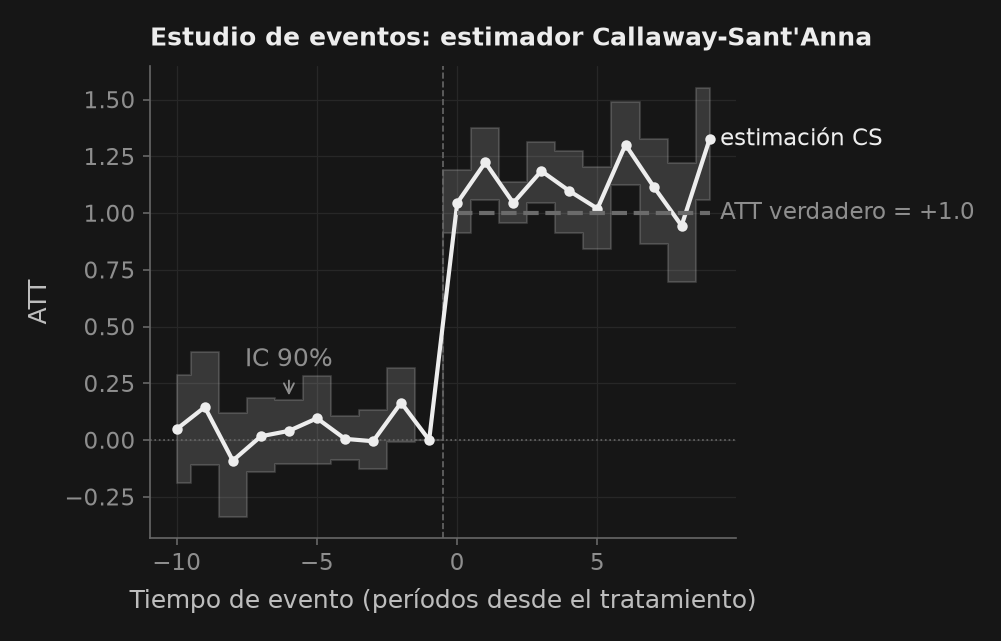

In [6]:
cols = _nbstyle.palette(2)
fig, ax = _nbstyle.figura()
ax.axhline(0.0, color=_nbstyle.SPINE, linewidth=0.8, linestyle=":")
ax.axvline(-0.5, color=_nbstyle.SPINE, linewidth=0.8, linestyle="--")
ax.fill_between(es_cs["event_time"], es_cs["lo"], es_cs["hi"], color=_nbstyle.BANDA,
                step="mid")
ax.plot(es_cs["event_time"], es_cs["att"], color=cols[0], ls="-", marker="o", markersize=4,
        label="estimación CS")
post_e = es_cs[es_cs["event_time"] >= 0]
ax.plot(post_e["event_time"], [TRUE_ATT] * len(post_e), color=cols[1],
        linestyle="--", label=f"ATT verdadero = {TRUE_ATT:+.1f}")
# the band is named over a placebo lead, where nothing else sits above it
r = es_cs[es_cs["event_time"] == -6].iloc[0]
ax.annotate("IC 90%", xy=(r["event_time"], r["hi"]), xytext=(0, 16),
            textcoords="offset points", ha="center", color=_nbstyle.NOTA,
            arrowprops=_nbstyle.FLECHA)
ax.set_xlabel("Tiempo de evento (períodos desde el tratamiento)")
ax.set_ylabel("ATT")
ax.set_title("Estudio de eventos: estimador Callaway-Sant'Anna")
ax.locator_params(axis="x", integer=True)   # event time counts whole periods
_nbstyle.etiquetar(ax, donde="fin")
plt.show()


### Dos caminos, un estimando: Callaway-Sant'Anna y Sun-Abraham

La ec. 3.4 de Callaway-Sant'Anna y el estimador IW de Sun-Abraham agregan la misma matriz $\text{ATT}(g, t)$ con las mismas cuotas de cohorte $n_g / \sum n_{g'}$, así que las dos sendas del estudio de eventos de abajo coinciden salvo redondeo de coma flotante (véase la diferencia que imprime la comprobación anterior). Lo que cambia es el resumen global que cada rutina reporta por defecto: $\hat{\theta}^O_{sel}$ promedia las tres medias de cohorte, mientras que el $\hat{\theta}^O_W$ de Sun-Abraham promedia las celdas post-tratamiento, lo que da el mayor peso a la cohorte $g = 5$, tratada durante más períodos. Con un efecto común todas las reglas apuntan a $+1.0$; el ejercicio final construye un panel donde las reglas se separan.

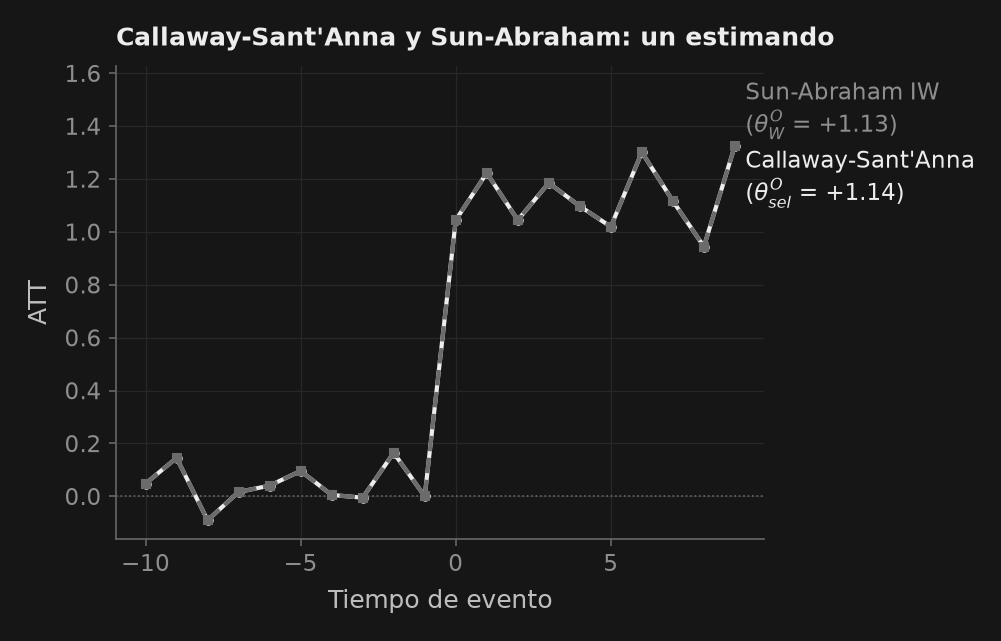

In [7]:
fig, ax = _nbstyle.figura()
ax.axhline(0.0, color=_nbstyle.SPINE, linewidth=0.8, linestyle=":")
ax.plot(es_cs["event_time"], es_cs["att"], color=cols[0], ls="-", marker="o", markersize=4,
        label=f"Callaway-Sant'Anna\n($\\theta^O_{{sel}}$ = {cs['sel']:+.2f})")
ax.plot(es_sa["event_time"], es_sa["att"], color=cols[1], marker="s",
        markersize=4, linestyle="--",
        label=f"Sun-Abraham IW\n($\\theta^O_W$ = {sa.att_overall:+.2f})")
ax.set_xlabel("Tiempo de evento")
ax.set_ylabel("ATT")
ax.set_ylim(top=es_cs["att"].max() + 0.30)   # room for the stacked names under the title
ax.set_title("Callaway-Sant'Anna y Sun-Abraham: un estimando")
ax.locator_params(axis="x", integer=True)   # event time counts whole periods
_nbstyle.etiquetar(ax, donde="fin", sep=3.0)   # las dos sendas coinciden: nombres apilados en dos líneas
plt.show()


### Análisis de los componentes básicos: trayectorias de grupo-tiempo por cohorte

El panel siguiente desagrega los efectos de tratamiento primitivos por grupo-tiempo $\text{ATT}(g, t)$ de forma individualizada para cada cohorte de adopción ($g=5, 8, 11$). Cada curva permanece en cero antes del tratamiento ($e < 0$) y pasa a gravitar en torno al valor verdadero $+1.0$ tras la adopción. Las estimaciones agregadas del estudio de eventos son promedios de estas trayectorias ponderados por el tamaño de cada cohorte.

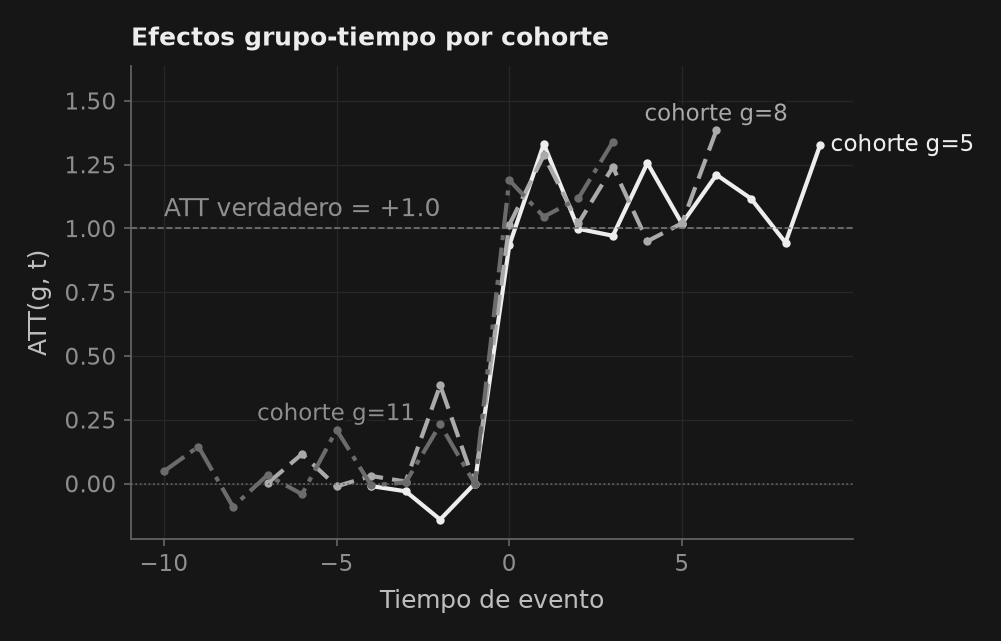

In [8]:
fig, ax = _nbstyle.figura()
gt = cells
cohorts = sorted(gt["g"].unique())
ccols = _nbstyle.palette(len(cohorts))
lineas = {}
for c, color in zip(cohorts, ccols):
    sub = gt[gt["g"] == c].sort_values("event_time")
    lineas[int(c)] = ax.plot(sub["event_time"], sub["att"], marker="o", markersize=3,
                             color=color, label=f"cohorte g={int(c)}")[0]
ax.axhline(0.0, color=_nbstyle.SPINE, linewidth=0.8, linestyle=":")
ax.axhline(TRUE_ATT, color=_nbstyle.gris("0.4"), linewidth=0.8, linestyle="--")
ax.annotate(f"ATT verdadero = {TRUE_ATT:+.1f}", xy=(gt["event_time"].min(), TRUE_ATT),
            xytext=(0, 3), textcoords="offset points", ha="left", va="bottom",
            color=_nbstyle.NOTA)
ax.set_ylim(top=gt["att"].max() + 0.25)      # room for a name above the highest point
ax.set_xlabel("Tiempo de evento")
ax.set_ylabel("ATT(g, t)")
ax.set_title("Efectos grupo-tiempo por cohorte")
ax.locator_params(axis="x", integer=True)   # event time counts whole periods
# each cohort is named where its path stands clear of the other two: g=5 after its
# last point, g=8 above its last point, g=11 above its pre-treatment peak
_nbstyle.etiquetar(ax, artistas=[lineas[5]], donde="fin")
_nbstyle.etiquetar(ax, artistas=[lineas[8]], donde=6.0)
_nbstyle.etiquetar(ax, artistas=[lineas[11]], donde=-5.0)
plt.show()


### Intuición econométrica: alineación de cohortes y el enmascaramiento del fallo de TWFE

En este ejercicio basal, las tres cohortes experimentan idéntico efecto estático $\tau = +1.0$. En consecuencia, sus trayectorias $\text{ATT}(g, t)$ oscilan en torno al mismo nivel $+1.0$, salvo por el ruido muestral. Al no existir crecimiento dinámico con el tiempo de exposición ($\Delta \text{ATT} = 0$), el término de comparaciones prohibidas en la descomposición de Goodman-Bacon se anula:
$$ \mathbb{E}[\hat{\beta}_{jk}^{2 \times 2, j}] = \text{ATT}_{j, post} - 0 = \text{ATT}_{j, post} $$
Esta especificación con efectos constantes enmascara por completo la fragilidad intrínseca del estimador TWFE. En la macroeconomía empírica real, las políticas casi nunca ejercen un impacto inmediato e invariante; su adopción es paulatina, los agentes ajustan sus conductas y el capital productivo se acumula con retraso. La sección siguiente introduce efectos dinámicos para evidenciar la quiebra de TWFE y la resolución mediante Callaway-Sant'Anna.

## 4. Experimento empírico interactivo: diagnóstico de ponderación negativa de TWFE y resolución con DiD escalonado

### El dilema económico: despliegue gradual de políticas macroeconómicas territoriales
Considere la adopción de una política a nivel regional o estatal —como un aumento progresivo de los salarios mínimos, deducciones tributarias corporativas o subsidios a la formación laboral— evaluada sobre paneles territoriales (`data_curso/paro_estatal_mensual.csv`).
Cuando una política entra en vigor gradualmente, su impacto causal se acumula en el tiempo: $\tau_i(e) = 1.0 + 1.2e$, donde $e = t - g$ es la exposición transcurrida. En las primeras oleadas de adopción, el efecto arranca en $+1.0$ y escala hasta superar $+15.0$ en los períodos finales.

### El experimento: demostración de la inversión catastrófica de signo
1. **Proceso generador de datos**: Construimos un panel de $N = 100$ unidades observadas durante $T = 16$ períodos con dos cohortes de adopción:
   - Cohorte 1 ($g_1 = 2$, 50 unidades): Adoptantes tempranas.
   - Cohorte 2 ($g_2 = 12$, 50 unidades): Adoptantes tardías.
   - Respuesta causal dinámica: $\tau(e) = 1.0 + 1.2e$ para todas las unidades tratadas ($D_{it} = 1$).
2. **Diagnóstico empírico**:
   - Calculamos el efecto medio verdadero sobre las celdas tratadas de este panel sin ruido ($t = 0, \dots, 15$): $\frac{1}{\sum D_{it}} \sum_{D_{it}=1} \tau_{it} = +7.467$. ¡Cada celda tratada tiene un impacto estrictamente positivo!
   - Obtenemos los pesos de regresión de Frisch-Waugh-Lovell $w_{it} = \tilde{D}_{it} / \sum \tilde{D}_{js}^2$ subyacentes a la regresión TWFE ingenua.
   - Constatamos la inversión de signo: TWFE arroja $\hat{\beta}^{TWFE} = -1.600$ debido a que el 22.2% de las celdas tratadas reciben pesos negativos (con una masa total de peso negativo de $-0.6667$).
3. **Resolución robusta a la heterogeneidad**:
   - El panel sin ruido no tiene unidades nunca tratadas, así que simulamos un segundo panel ($t = 1, \dots, 16$) que añade 20 unidades nunca tratadas y ruido, y estimamos Callaway & Sant'Anna (2021) con las funciones de la Sección 2.
   - Comparamos cada resumen con su propio valor plantado en ese segundo panel: $\theta^O_{sel}$, el promedio ponderado por tamaño de los efectos medios de las dos cohortes, y $\theta^O_W$, el promedio sobre celdas tratadas. Difieren porque la cohorte temprana está tratada durante 15 períodos y la tardía durante 5.
   - Cargamos el panel empírico de desempleo estatal de `data_curso/paro_estatal_mensual.csv` para verificar la estructura territorial real.

DIAGNÓSTICO DE PONDERACIÓN NEGATIVA TWFE (EFECTOS DINÁMICOS)
Efecto medio de tratamiento sobre tratados (ATT): +7.467  (estrictamente positivo)
Estimación MCO TWFE de libro de texto (beta)    : -1.600  (¡INVERSIÓN DE SIGNO!)
Porcentaje de celdas tratadas con peso negativo : 22.2%
Masa total de peso negativo en unidades tratadas: -0.6667
CS theta^O_sel (ec. 3.11) en este panel    : +6.391  (plantado +6.400; IC 90% [+5.913, +6.842])
CS theta^O_W   (ec. 3.10) en este panel    : +7.890  (plantado +7.900)
Medias de cohorte CS theta_sel(g)          : g=2: +9.39, g=12: +3.39
Benchmark TWFE ingenuo en panel (SE conglomerado) : -0.973 (SE: 0.444)
Panel laboral empírico incorporado                 : 51 estados/jurisdicciones


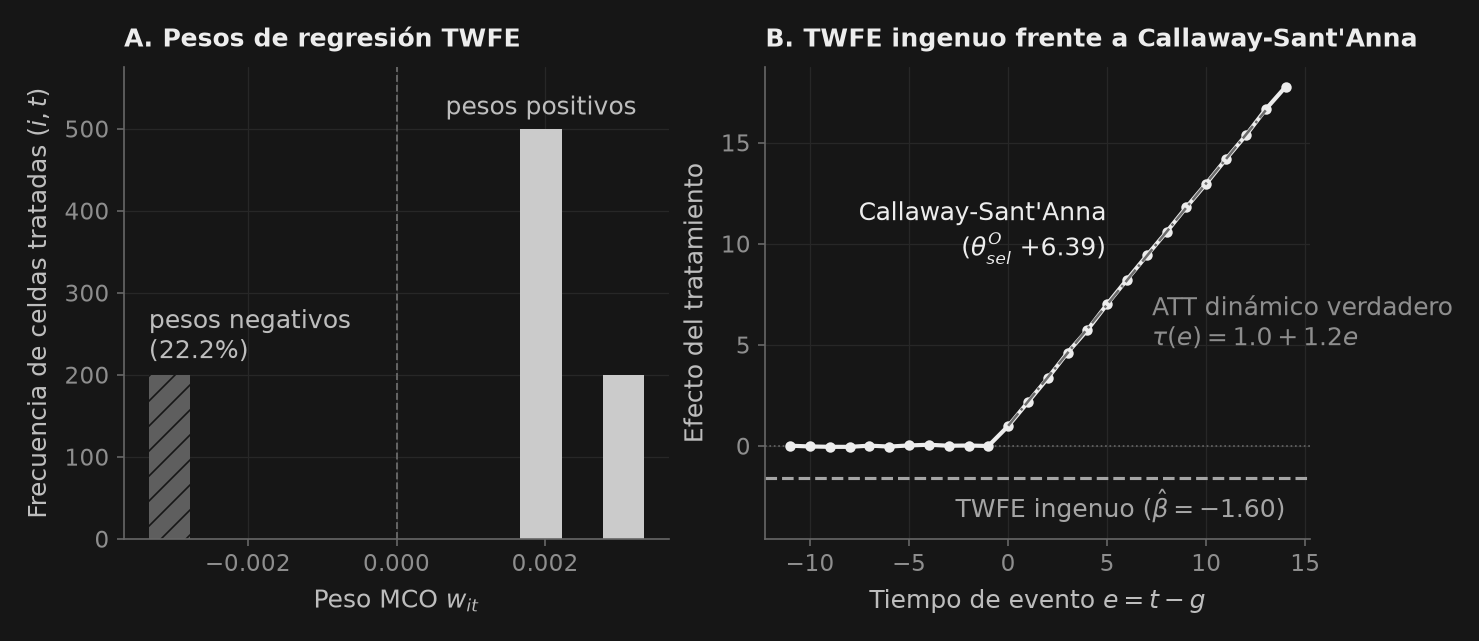

In [9]:
from pathlib import Path
from puremacro.regress import ols

# 1. Simulate panel with dynamic treatment effects: tau(e) = 1.0 + 1.2*e
N, T = 100, 16
g_assign = [2] * 50 + [12] * 50

rows_diag = []
for i in range(N):
    g = g_assign[i]
    for t in range(T):
        d = 1 if t >= g else 0
        tau = (1.0 + 1.2 * (t - g)) if d == 1 else 0.0
        rows_diag.append({"unit": i, "time": t, "g": g, "D": d, "tau": tau})

df_diag = pd.DataFrame(rows_diag)

# Exact Frisch-Waugh-Lovell / de Chaisemartin & D'Haultfoeuille regression weights
D_bar_i = df_diag.groupby("unit")["D"].transform("mean")
D_bar_t = df_diag.groupby("time")["D"].transform("mean")
D_bar = df_diag["D"].mean()
df_diag["D_tilde"] = df_diag["D"] - D_bar_i - D_bar_t + D_bar
denom = (df_diag["D_tilde"] ** 2).sum()
df_diag["w_it"] = df_diag["D_tilde"] / denom

# Compute headline diagnostic metrics via puremacro.regress.ols with clustered SE
true_att = float(df_diag[df_diag["D"] == 1]["tau"].mean())
tau_tilde = (df_diag["tau"] - df_diag.groupby("unit")["tau"].transform("mean")
             - df_diag.groupby("time")["tau"].transform("mean") + df_diag["tau"].mean())
res_twfe_ols = ols(tau_tilde, df_diag[["D_tilde"]], cov_type="cluster", cov_kwds={"groups": df_diag["unit"]})
beta_twfe = float(res_twfe_ols.params["D_tilde"])
neg_weights_share = float((df_diag[df_diag["D"] == 1]["w_it"] < 0).mean())
neg_weight_mass = float(df_diag[(df_diag["D"] == 1) & (df_diag["w_it"] < 0)]["w_it"].sum())

print("=" * 68)
print("DIAGNÓSTICO DE PONDERACIÓN NEGATIVA TWFE (EFECTOS DINÁMICOS)")
print("=" * 68)
print(f"Efecto medio de tratamiento sobre tratados (ATT): {true_att:+.3f}  (estrictamente positivo)")
print(f"Estimación MCO TWFE de libro de texto (beta)    : {beta_twfe:+.3f}  (¡INVERSIÓN DE SIGNO!)")
print(f"Porcentaje de celdas tratadas con peso negativo : {neg_weights_share * 100:.1f}%")
print(f"Masa total de peso negativo en unidades tratadas: {neg_weight_mass:+.4f}")
print("=" * 68)

# 2. Resolución robusta a la heterogeneidad: Callaway & Sant'Anna a mano (funciones de la Sección 2)
rows_cs = []
rng_dyn = np.random.default_rng(2024)
unit_fe_dyn = rng_dyn.standard_normal(120) * 0.4
time_fe_dyn = rng_dyn.standard_normal(T) * 0.2

for i in range(120):
    g = 2.0 if i < 50 else (12.0 if i < 100 else np.nan)
    for t in range(1, T + 1):
        d = 1 if (not np.isnan(g) and t >= g) else 0
        tau = (1.0 + 1.2 * (t - g)) if d == 1 else 0.0
        y = unit_fe_dyn[i] + time_fe_dyn[t - 1] + tau + 0.15 * rng_dyn.standard_normal()
        rows_cs.append({"unit": i, "time": t, "y": y, "treat_time": g, "D": d, "tau": tau})

df_cs_dyn = pd.DataFrame(rows_cs)
cs_dyn = cs_bootstrap(df_cs_dyn)
treated = df_cs_dyn[df_cs_dyn["D"] == 1]
n_dyn = treated.groupby("treat_time")["unit"].nunique()
tau_g = treated.groupby("treat_time")["tau"].mean()             # theta_sel(g) plantado
truth_sel = float((tau_g * n_dyn).sum() / n_dyn.sum())             # theta^O_sel plantado
truth_W = float(treated["tau"].mean())                            # theta^O_W plantado
print(f"CS theta^O_sel (ec. 3.11) en este panel    : {cs_dyn['sel']:+.3f}  (plantado {truth_sel:+.3f}; "
      f"IC 90% [{cs_dyn['sel_lo']:+.3f}, {cs_dyn['sel_hi']:+.3f}])")
print(f"CS theta^O_W   (ec. 3.10) en este panel    : {cs_dyn['simple']:+.3f}  (plantado {truth_W:+.3f})")
print("Medias de cohorte CS theta_sel(g)          : "
      + ", ".join(f"g={int(g)}: {v:+.2f}" for g, v in zip(cs_dyn["cohorts"], cs_dyn["theta_g"])))

# Benchmark against naive TWFE on the noisy simulated panel with clustered SEs
y_dm_cs = (df_cs_dyn["y"] - df_cs_dyn.groupby("unit")["y"].transform("mean")
           - df_cs_dyn.groupby("time")["y"].transform("mean") + df_cs_dyn["y"].mean())
D_dm_cs = (df_cs_dyn["D"] - df_cs_dyn.groupby("unit")["D"].transform("mean")
           - df_cs_dyn.groupby("time")["D"].transform("mean") + df_cs_dyn["D"].mean())
res_twfe_dyn = ols(y_dm_cs, D_dm_cs.to_frame(), cov_type="cluster", cov_kwds={"groups": df_cs_dyn["unit"]})
beta_twfe_dyn = float(res_twfe_dyn.params.iloc[0])
se_twfe_dyn = float(res_twfe_dyn.bse.iloc[0])
print(f"Benchmark TWFE ingenuo en panel (SE conglomerado) : {beta_twfe_dyn:+.3f} (SE: {se_twfe_dyn:.3f})")

# 3. Load empirical state unemployment panel from data_curso
from _datos import ruta_dato
df_states = pd.read_csv(ruta_dato("paro_estatal_mensual.csv"))
n_states = df_states["code"].nunique()
print(f"Panel laboral empírico incorporado                 : {n_states} estados/jurisdicciones")

# Numerical verification checks
assert true_att > 7.0, f"Expected true ATT > 7.0, got {true_att:.3f}"
assert beta_twfe < 0.0, f"Expected negative TWFE beta, got {beta_twfe:.3f}"
assert beta_twfe_dyn < 0.0, f"Expected negative TWFE panel beta, got {beta_twfe_dyn:.3f}"
assert res_twfe_dyn.bse.iloc[0] > 0.0, "Clustered SE must be strictly positive"
assert neg_weights_share > 0.20, f"Expected >20% negative weights, got {neg_weights_share:.3f}"
assert neg_weight_mass < -0.50, f"Expected negative weight mass < -0.50, got {neg_weight_mass:.3f}"
assert abs(cs_dyn["sel"] - truth_sel) < 0.3, (cs_dyn["sel"], truth_sel)
assert abs(cs_dyn["simple"] - truth_W) < 0.3, (cs_dyn["simple"], truth_W)
assert n_states == 51, f"Expected 51 state series in paro_estatal_mensual, got {n_states}"

# Visual Diagnostic Plot
fig, (ax1, ax2) = _nbstyle.figura(1, 2)

# Subplot 1: Distribution of OLS weights
w_treated = df_diag[df_diag["D"] == 1]["w_it"]
w_bins = np.linspace(w_treated.min(), w_treated.max(), 13)  # 12 bins shared by both groups
n_pos, _, _ = ax1.hist(w_treated[w_treated >= 0], bins=w_bins, color=_nbstyle.BARRA_COLORES[0])
n_neg, _, _ = ax1.hist(w_treated[w_treated < 0], bins=w_bins, color=_nbstyle.BARRA_COLORES[2], hatch="//")
ax1.axvline(0.0, color=_nbstyle.SPINE, linewidth=0.9, linestyle="--")
# each group is named over its tallest bar
centros = 0.5 * (w_bins[1:] + w_bins[:-1])
k_pos, k_neg = int(np.argmax(n_pos)), int(np.argmax(n_neg))
ax1.annotate("pesos positivos", xy=(centros[k_pos], n_pos[k_pos]), xytext=(0, 4),
             textcoords="offset points", ha="center", va="bottom", color=_nbstyle.TEXTO)
ax1.annotate(f"pesos negativos\n({neg_weights_share * 100:.1f}%)", xy=(w_bins[k_neg], n_neg[k_neg]),
             xytext=(0, 4), textcoords="offset points", ha="left", va="bottom", color=_nbstyle.TEXTO)
ax1.set_ylim(0, 1.15 * max(n_pos.max(), n_neg.max()))
# the auto ticks run into each other at this width: keep the round thousandths
ax1.locator_params(axis="x", nbins=4)
ax1.set_xlabel("Peso MCO $w_{it}$")
ax1.set_ylabel("Frecuencia de celdas tratadas $(i, t)$")
ax1.set_title("A. Pesos de regresión TWFE")

# Subplot 2: Causal recovery comparison
es_dyn = cs_dyn["es_table"]
ax2.axhline(0.0, color=_nbstyle.SPINE, linewidth=0.8, linestyle=":")
ax2.axhline(beta_twfe, color=_nbstyle.S2["color"], linestyle="--", linewidth=1.5)
ax2.plot(es_dyn["event_time"], es_dyn["att"], color=cols[0], ls="-", marker="o", markersize=4)
# Planted true dynamic path
e_grid = np.arange(0, 14)
ax2.plot(e_grid, 1.0 + 1.2 * e_grid, color=_nbstyle.S3["color"], linestyle="-.", linewidth=1.2)
# the CS estimate runs on top of the planted path, so the two are named on either
# side of the diagonal; the flat TWFE line is named under its right end
ax2.annotate(f"Callaway-Sant'Anna\n($\\theta^O_{{sel}}$ {cs_dyn['sel']:+.2f})", xy=(6, 1.0 + 1.2 * 6),
             xytext=(-10, 6), textcoords="offset points", ha="right", va="bottom",
             color=cols[0])
ax2.annotate("ATT dinámico verdadero\n$\\tau(e) = 1.0 + 1.2e$", xy=(6, 1.0 + 1.2 * 6),
             xytext=(12, -6), textcoords="offset points", ha="left", va="top",
             color=_nbstyle.NOTA)
ax2.annotate(f"TWFE ingenuo ($\\hat{{\\beta}} = {beta_twfe:+.2f}$)",
             xy=(es_dyn["event_time"].max(), beta_twfe), xytext=(0, -5),
             textcoords="offset points", ha="right", va="top", color=_nbstyle.S2["color"])
ax2.set_ylim(bottom=beta_twfe - 3.0)
ax2.set_xlabel("Tiempo de evento $e = t - g$")
ax2.set_ylabel("Efecto del tratamiento")
ax2.set_title("B. TWFE ingenuo frente a Callaway-Sant'Anna")

plt.show()

## 5. Síntesis para la política macroeconómica: lecciones para la investigación aplicada

El diagnóstico cuantitativo anterior demuestra la magnitud del fallo de TWFE en la macroeconomía empírica:
1. **El mecanismo de inversión de signo**: Cuando los efectos del tratamiento se consolidan de forma paulatina ($\tau(e) = 1.0 + 1.2e$), las unidades tratadas antes ($g_1 = 2$) experimentan una fuerte expansión entre $t = 2$ y $t = 16$. Cuando la cohorte posterior ($g_2 = 12$) adopta la medida en el período 12, MCO emplea a la cohorte temprana como grupo de control. Dado que las adoptantes tempranas siguen creciendo a lo largo de su senda de tratamiento, la doble diferenciación resta este crecimiento acumulado de las adoptantes tardías, generando **un 22.2% de pesos negativos** e invirtiendo un efecto de política estrictamente positivo ($+7.467$) en una contracción espuria ($-1.600$).
2. **El imperativo de las comparaciones limpias**: Callaway & Sant'Anna (2021) y Sun & Abraham (2021) resuelven la crisis garantizando que las unidades ya tratadas *nunca* ejerzan de controles. Al calcular diferencias exclusivamente frente a contrafactuales limpios (nunca tratados o aún no tratados), recuperan la senda dinámica plantada, y cada resumen su propio valor plantado: $\hat{\theta}^O_{sel} = +6.391$ frente a $+6.400$, y $\hat{\theta}^O_W = +7.890$ frente a $+7.900$. Los dos resúmenes difieren porque responden a preguntas distintas: $\theta^O_{sel}$ promedia los efectos medios de las dos cohortes ($+9.39$ y $+3.39$), mientras que $\theta^O_W$ promedia celdas, y la cohorte temprana aporta 15 de cada 20. El intervalo al 90% de $\hat{\theta}^O_{sel}$, $[+5.913, +6.842]$, es amplio aunque cada coeficiente del estudio de eventos se estima con precisión: remuestrear unidades vuelve a sortear también las cuotas de cohorte, y las dos medias de cohorte están muy alejadas.
3. **Pautas metodológicas para la macroeconomía aplicada**:
   - Nunca reporte un coeficiente estático $\hat{\beta}^{TWFE}$ sin inspeccionar previamente la distribución de pesos diagnósticos (Goodman-Bacon 2021; de Chaisemartin & D'Haultfoeuille 2020).
   - Ante adopciones escalonadas en el tiempo, recurra por defecto a estimadores limpios (`puremacro.did.callaway_santanna`, `puremacro.did.sun_abraham` o `puremacro.lp.lp_did`).
   - Examine los adelantos placebo ($e \le -2$) para evaluar con rigor las tendencias paralelas, teniendo en cuenta que el período base $e = -1$ está normalizado a cero por construcción.

El siguiente cuaderno, `T05_D_lp_did_es`, traslada este principio de control limpio al marco de las proyecciones locales de Jordà (2005), posibilitando la estimación de respuestas al impulso, dependencias de estado y variables instrumentales en la inferencia causal con datos de panel.

## 6. Tu turno: ¿cuándo importan los pesos de las cohortes?

El panel de la Sección 2 tenía cohortes casi iguales y un único efecto común, así que todas las reglas de ponderación daban casi la misma respuesta. La celda siguiente construye un panel **sin ruido** donde las reglas se separan: una cohorte temprana ($g = 3$, `N_EARLY` unidades) cuyo efecto crece $1.0, 1.5, 2.0, 2.5$ en $t = 3, \dots, 6$; una cohorte tardía ($g = 5$, 40 unidades) con efectos $3.0, 4.0$; y 50 unidades nunca tratadas. Sin ruido, `cs_by_hand` debe reproducir exactamente los valores plantados, de modo que las comprobaciones califican tu razonamiento y no la suerte muestral.

1. **(básico)** Antes de ejecutar, predice $\theta_{es}(0)$ con `N_EARLY = 10` y con `N_EARLY = 80`. ¿Hacia el efecto de impacto de qué cohorte se desplaza el estudio de eventos cuando crece la cohorte temprana?
2. **(intermedio)** La regla de pesos iguales (cada cohorte cuenta una vez, que es lo que reporta `callaway_santanna(..., aggregation="unweighted")`) da $\theta_{es}(0) = (1.0 + 3.0)/2 = 2.0$ sean cuales sean los tamaños. ¿Con qué `N_EARLY` coincide con la ec. 3.4, y por qué solo ahí?
3. **(avanzado)** Demuestra en papel que en este diseño $\theta^O_W < \theta^O_{sel}$ para cualesquiera tamaños positivos (pista: el numerador de $\theta^O_{sel} - \theta^O_W$ es $3.5\, n_{early}\, n_{late}$). ¿Qué cohorte sobrepondera el resumen ponderado por celdas, y por qué?

In [10]:
N_EARLY = 10     # ← cambia esto: tamaño de la cohorte temprana (g = 3), cualquier entero de 1 a 200
N_LATE, N_NEVER = 40, 50
EFFECT = {3: {3: 1.0, 4: 1.5, 5: 2.0, 6: 2.5}, 5: {5: 3.0, 6: 4.0}}   # ATT(g, t) plantado

rows_toy, uid = [], 0
for g, n in [(3, N_EARLY), (5, N_LATE), (np.nan, N_NEVER)]:
    for _ in range(n):
        for t in range(1, 7):
            tau = 0.0 if np.isnan(g) else EFFECT[g].get(t, 0.0)
            rows_toy.append({"unit": uid, "time": t, "y": 0.1 * uid + 0.5 * t + tau,
                             "treat_time": g})     # efectos de unidad y de tiempo, sin ruido
        uid += 1
toy = cs_by_hand(*to_wide(pd.DataFrame(rows_toy)))

share = N_EARLY / (N_EARLY + N_LATE)                         # cuota de la cohorte temprana entre las tratadas
truth_e0 = share * 1.0 + (1 - share) * 3.0                   # ec. 3.4 en e = 0
truth_sel = share * np.mean(list(EFFECT[3].values())) + (1 - share) * np.mean(list(EFFECT[5].values()))
es0 = float(toy["es"][toy["event_time"] == 0][0])
equal_e0 = (1.0 + 3.0) / 2                                   # cada cohorte cuenta una vez
# los mismos dos estudios de eventos según la biblioteca: por defecto (ec. 3.4) y con pesos iguales
es_lib = callaway_santanna(pd.DataFrame(rows_toy), n_boot=0).att_event_study.set_index("event_time")["att"]
es_unw = callaway_santanna(pd.DataFrame(rows_toy), n_boot=0,
                           aggregation="unweighted").att_event_study.set_index("event_time")["att"]

print(f"N_EARLY = {N_EARLY}: theta_es(0) = {es0:.4f}  (plantado {truth_e0:.4f}; pesos iguales {equal_e0:.4f})")
print(f"theta^O_sel = {toy['sel']:.4f}  (plantado {truth_sel:.4f});  theta^O_W = {toy['simple']:.4f}")
print(f"callaway_santanna theta_es(0): por defecto {es_lib[0]:.4f} | aggregation='unweighted' {es_unw[0]:.4f}")

assert N_EARLY == int(N_EARLY) and 1 <= N_EARLY <= 200
assert abs(es0 - truth_e0) < 1e-10                          # la ec. 3.4 recupera la senda plantada
assert abs(toy["sel"] - truth_sel) < 1e-10                  # la ec. 3.11 recupera el resumen plantado
assert np.isclose(es0, equal_e0) == (N_EARLY == N_LATE)     # pesos iguales coinciden solo si los tamaños coinciden
assert toy["simple"] < toy["sel"]                           # los pesos por celda se inclinan hacia g = 3
assert abs(es_lib[0] - es0) < 1e-10 and abs(es_unw[0] - equal_e0) < 1e-10   # la biblioteca coincide

N_EARLY = 10: theta_es(0) = 2.6000  (plantado 2.6000; pesos iguales 2.0000)
theta^O_sel = 3.1500  (plantado 3.1500);  theta^O_W = 2.9167
callaway_santanna theta_es(0): por defecto 2.6000 | aggregation='unweighted' 2.0000
